In [2]:
import os

data_folder = os.path.join(os.getcwd(), "data")

print("Project folder:", os.getcwd())
print("Data folder exists:", os.path.exists(data_folder))

if os.path.exists(data_folder):
    print("\nFiles and folders inside data:")
    for item in os.listdir(data_folder):
        print(item)

Project folder: C:\Users\hp-laptop\Downloads\lumbar spine project
Data folder exists: True

Files and folders inside data:
.ipynb_checkpoints
Lumbar_spine_ML_project.ipynb
processed_lsd
processed_lsd_jpgs
processed_osf
processed_osf_jpgs
processed_spider
processed_spider_jpgs
processed_tseg
processed_tseg_jpgs


In [3]:
import os

for item in os.listdir(data_folder):
    path = os.path.join(data_folder, item)

    if os.path.isdir(path):
        npy_count = 0
        image_count = 0
        excel_count = 0

        for root, dirs, files in os.walk(path):
            for file in files:
                ext = os.path.splitext(file)[1].lower()

                if ext == ".npy":
                    npy_count += 1
                elif ext in [".png", ".jpg", ".jpeg"]:
                    image_count += 1
                elif ext in [".xlsx", ".xls", ".csv"]:
                    excel_count += 1

        print(f"\nFolder: {item}")
        print(f"NPY files: {npy_count}")
        print(f"Image files: {image_count}")
        print(f"Excel/CSV files: {excel_count}")

    else:
        print("File:", item)


Folder: .ipynb_checkpoints
NPY files: 0
Image files: 0
Excel/CSV files: 0
File: Lumbar_spine_ML_project.ipynb

Folder: processed_lsd
NPY files: 515
Image files: 0
Excel/CSV files: 1

Folder: processed_lsd_jpgs
NPY files: 0
Image files: 515
Excel/CSV files: 0

Folder: processed_osf
NPY files: 34
Image files: 0
Excel/CSV files: 0

Folder: processed_osf_jpgs
NPY files: 0
Image files: 34
Excel/CSV files: 0

Folder: processed_spider
NPY files: 210
Image files: 0
Excel/CSV files: 1

Folder: processed_spider_jpgs
NPY files: 0
Image files: 210
Excel/CSV files: 0

Folder: processed_tseg
NPY files: 478
Image files: 0
Excel/CSV files: 0

Folder: processed_tseg_jpgs
NPY files: 0
Image files: 478
Excel/CSV files: 0


In [4]:
import os

for root, dirs, files in os.walk(data_folder):
    for file in files:
        if file.lower().endswith((".xlsx", ".xls", ".csv")):
            print(os.path.join(root, file))

C:\Users\hp-laptop\Downloads\lumbar spine project\data\processed_lsd\lumbar_mri_features.csv
C:\Users\hp-laptop\Downloads\lumbar spine project\data\processed_spider\metadata.csv


In [5]:
import pandas as pd
import os

file1 = os.path.join(
    data_folder, "processed_lsd", "lumbar_mri_features.csv"
)

file2 = os.path.join(
    data_folder, "processed_spider", "metadata.csv"
)

df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

print("=== LUMBAR MRI FEATURES ===")
print("Shape:", df1.shape)
print("Columns:", df1.columns.tolist())
display(df1.head())

print("\n=== SPIDER METADATA ===")
print("Shape:", df2.shape)
print("Columns:", df2.columns.tolist())
display(df2.head())

=== LUMBAR MRI FEATURES ===
Shape: (515, 7)
Columns: ['filename', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity', 'median_intensity', 'nonzero_ratio']


,filename,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity,nonzero_ratio
0,0001.npy,56.446125,73.245030,0.0,255.0,19.0,0.817888
1,0002.npy,49.424150,67.427970,0.0,255.0,18.0,0.824352
2,0003.npy,40.403126,49.505750,0.0,255.0,21.0,0.847771
3,0004.npy,41.224136,56.580276,0.0,255.0,14.0,0.839513
4,0005.npy,48.762200,63.903680,0.0,255.0,20.0,0.836703



=== SPIDER METADATA ===
Shape: (210, 7)
Columns: ['height', 'width', 'n_frames', 'idx', 'study_id', 'fold', 'series_description']


,height,width,n_frames,idx,study_id,fold,series_description
0,256,256,50,1_t2,1,1,Sagittal T2/STIR
1,256,256,15,10_t2,10,1,Sagittal T2/STIR
2,256,256,21,100_t2,100,1,Sagittal T2/STIR
3,256,256,17,101_t2,101,0,Sagittal T2/STIR
4,256,256,15,104_t2,104,1,Sagittal T2/STIR


In [6]:
print("Dataset information:")
df1.info()

print("\nMissing values:")
print(df1.isnull().sum())

print("\nDuplicate rows:", df1.duplicated().sum())

print("\nStatistical summary:")
display(df1.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   filename          515 non-null    str    
 1   mean_intensity    515 non-null    float64
 2   std_intensity     515 non-null    float64
 3   min_intensity     515 non-null    float64
 4   max_intensity     515 non-null    float64
 5   median_intensity  515 non-null    float64
 6   nonzero_ratio     515 non-null    float64
dtypes: float64(6), str(1)
memory usage: 32.3 KB

Missing values:
filename            0
mean_intensity      0
std_intensity       0
min_intensity       0
max_intensity       0
median_intensity    0
nonzero_ratio       0
dtype: int64

Duplicate rows: 0

Statistical summary:


,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity,nonzero_ratio
count,515.000000,515.000000,515.0,515.0,515.000000,515.000000
mean,53.696840,68.707235,0.0,255.0,19.957282,0.833004
std,9.465082,6.773346,0.0,0.0,9.376378,0.012024
min,28.251300,44.487724,0.0,255.0,8.000000,0.767992
25%,47.361742,64.059082,0.0,255.0,15.000000,0.831555
50%,52.877990,68.823650,0.0,255.0,18.000000,0.836908
75%,58.736042,73.533947,0.0,255.0,22.000000,0.838890
max,101.040120,87.544930,0.0,255.0,93.000000,0.850083


In [7]:
from sklearn.preprocessing import StandardScaler

# Select features that vary across the dataset
feature_columns = [
    "mean_intensity",
    "std_intensity",
    "median_intensity",
    "nonzero_ratio"
]

X = df1[feature_columns].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original dataset shape:", df1.shape)
print("Selected features:", feature_columns)
print("Scaled feature shape:", X_scaled.shape)
print("All values finite:", __import__("numpy").isfinite(X_scaled).all())

Original dataset shape: (515, 7)
Selected features: ['mean_intensity', 'std_intensity', 'median_intensity', 'nonzero_ratio']
Scaled feature shape: (515, 4)
All values finite: True


In [ ]:
# apply K-means clustering

In [8]:
from sklearn.cluster import KMeans
import pandas as pd

# Create the K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
df1["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

# Count records in each cluster
print("K-Means clustering completed!")
print("\nRecords in each cluster:")
print(df1["kmeans_cluster"].value_counts().sort_index())

# Show the first 10 results
display(
    df1[
        ["filename", "mean_intensity", "std_intensity",
         "median_intensity", "nonzero_ratio", "kmeans_cluster"]
    ].head(10)
)

K-Means clustering completed!

Records in each cluster:
kmeans_cluster
0     42
1     10
2    216
3    115
4    132
Name: count, dtype: int64


,filename,mean_intensity,std_intensity,median_intensity,nonzero_ratio,kmeans_cluster
0,0001.npy,56.446125,73.245030,19.0,0.817888,2
1,0002.npy,49.424150,67.427970,18.0,0.824352,2
2,0003.npy,40.403126,49.505750,21.0,0.847771,4
3,0004.npy,41.224136,56.580276,14.0,0.839513,4
4,0005.npy,48.762200,63.903680,20.0,0.836703,4
5,0006.npy,46.687960,62.990265,18.0,0.837318,4
6,0007.npy,60.393520,67.994675,30.0,0.838846,2
7,0008.npy,44.603012,66.055435,8.0,0.837407,4
8,0009.npy,54.638725,73.098580,16.0,0.840354,2
9,0010.npy,60.733322,74.350270,24.0,0.838933,3


In [9]:
import os
from collections import Counter

for folder in sorted(os.listdir(data_folder)):
    path = os.path.join(data_folder, folder)

    if os.path.isdir(path):
        counts = Counter()

        for root, dirs, files in os.walk(path):
            for file in files:
                ext = os.path.splitext(file)[1].lower()
                counts[ext or "no extension"] += 1

        print(f"\n{folder}")
        print("File counts:", dict(counts))


.ipynb_checkpoints
File counts: {'.ipynb': 1}

processed_lsd
File counts: {'.npy': 515, '.csv': 1, '.ipynb': 2}

processed_lsd_jpgs
File counts: {'.jpg': 515}

processed_osf
File counts: {'.npy': 34}

processed_osf_jpgs
File counts: {'.jpg': 34}

processed_spider
File counts: {'.npy': 210, '.csv': 1}

processed_spider_jpgs
File counts: {'.jpg': 210}

processed_tseg
File counts: {'.npy': 478}

processed_tseg_jpgs
File counts: {'.jpg': 478}


In [10]:
import os
import numpy as np
from collections import Counter

folders = [
    "processed_lsd",
    "processed_osf",
    "processed_spider",
    "processed_tseg"
]

for folder in folders:
    folder_path = os.path.join(data_folder, folder)
    shapes = Counter()
    errors = 0

    for file in os.listdir(folder_path):
        if file.lower().endswith(".npy"):
            try:
                arr = np.load(
                    os.path.join(folder_path, file),
                    mmap_mode="r"
                )
                shapes[str(arr.shape)] += 1
            except Exception:
                errors += 1

    print(f"\n{folder}")
    print("Array shapes and counts:", dict(shapes))
    print("Files that could not be read:", errors)


processed_lsd
Array shapes and counts: {'(256, 256, 15)': 485, '(256, 256, 13)': 2, '(256, 256, 30)': 17, '(256, 256, 25)': 5, '(256, 256, 16)': 1, '(256, 256, 45)': 1, '(256, 256, 32)': 1, '(256, 256, 20)': 3}
Files that could not be read: 0

processed_osf
Array shapes and counts: {'(256, 256, 15)': 14, '(256, 256, 19)': 3, '(256, 256, 17)': 6, '(256, 256, 14)': 1, '(256, 256, 11)': 3, '(256, 256, 18)': 3, '(256, 256, 21)': 2, '(256, 256, 22)': 1, '(256, 256, 20)': 1}
Files that could not be read: 0

processed_spider
Array shapes and counts: {'(256, 256, 21)': 8, '(256, 256, 17)': 31, '(256, 256, 15)': 30, '(256, 256, 25)': 11, '(256, 256, 33)': 4, '(256, 256, 24)': 26, '(256, 256, 26)': 16, '(256, 256, 20)': 8, '(256, 256, 19)': 14, '(256, 256, 27)': 13, '(256, 256, 22)': 3, '(256, 256, 16)': 6, '(256, 256, 28)': 5, '(256, 256, 36)': 2, '(256, 256, 35)': 2, '(256, 256, 18)': 9, '(256, 256, 30)': 6, '(256, 256, 31)': 2, '(256, 256, 43)': 1, '(256, 256, 29)': 1, '(256, 256, 32)': 4, '

In [11]:
#extract features from all four folders

import os
import numpy as np
import pandas as pd

folders = [
    "processed_lsd",
    "processed_osf",
    "processed_spider",
    "processed_tseg"
]

all_features = []

for folder in folders:
    folder_path = os.path.join(data_folder, folder)

    for file in sorted(os.listdir(folder_path)):
        if file.lower().endswith(".npy"):
            path = os.path.join(folder_path, file)
            volume = np.load(path).astype(np.float32)

            all_features.append({
                "source_folder": folder,
                "filename": file,
                "n_slices": volume.shape[2],
                "mean_intensity": volume.mean(),
                "std_intensity": volume.std(),
                "min_intensity": volume.min(),
                "max_intensity": volume.max(),
                "median_intensity": np.median(volume),
                "nonzero_ratio": np.count_nonzero(volume) / volume.size
            })

combined_df = pd.DataFrame(all_features)

print("Combined dataset shape:", combined_df.shape)
print("\nRecords per source folder:")
print(combined_df["source_folder"].value_counts())

display(combined_df.head())

Combined dataset shape: (1237, 9)

Records per source folder:
source_folder
processed_lsd       515
processed_tseg      478
processed_spider    210
processed_osf        34
Name: count, dtype: int64


,source_folder,filename,n_slices,mean_intensity,std_intensity,min_intensity,max_intensity,median_intensity,nonzero_ratio
0,processed_lsd,0001.npy,15,56.446125,73.245033,0.0,255.0,19.0,0.817888
1,processed_lsd,0002.npy,15,49.424149,67.427971,0.0,255.0,18.0,0.824352
2,processed_lsd,0003.npy,15,40.403126,49.505749,0.0,255.0,21.0,0.847771
3,processed_lsd,0004.npy,15,41.224136,56.580276,0.0,255.0,14.0,0.839513
4,processed_lsd,0005.npy,15,48.762199,63.903679,0.0,255.0,20.0,0.836703


In [12]:
# check data quality

print("Missing values:")
print(combined_df.isnull().sum())

print("\nDuplicate records:")
print(combined_df.duplicated(
    subset=["source_folder", "filename"]
).sum())

print("\nAverage features by dataset:")
display(
    combined_df.groupby("source_folder")[
        ["mean_intensity", "std_intensity",
         "median_intensity", "nonzero_ratio", "n_slices"]
    ].mean().round(3)
)

Missing values:
source_folder       0
filename            0
n_slices            0
mean_intensity      0
std_intensity       0
min_intensity       0
max_intensity       0
median_intensity    0
nonzero_ratio       0
dtype: int64

Duplicate records:
0

Average features by dataset:


,mean_intensity,std_intensity,median_intensity,nonzero_ratio,n_slices
source_folder,,,,,
processed_lsd,53.696999,68.707001,19.957001,0.833,15.707
processed_osf,31.353001,36.513000,20.059000,0.757,16.294
processed_spider,65.932999,78.862000,30.295000,0.723,22.052
processed_tseg,43.287998,45.132000,26.782000,0.489,16.000


In [13]:
# prepare full dataset for clustering

from sklearn.preprocessing import StandardScaler

# Select numerical features for clustering
feature_columns = [
    "mean_intensity",
    "std_intensity",
    "median_intensity",
    "nonzero_ratio",
    "n_slices"
]

X = combined_df[feature_columns].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

print("\nMean of scaled features:")
print(X_scaled.mean(axis=0).round(3))

print("\nStandard deviation of scaled features:")
print(X_scaled.std(axis=0).round(3))

Original feature shape: (1237, 5)
Scaled feature shape: (1237, 5)

Mean of scaled features:
[ 0.  0. -0. -0. -0.]

Standard deviation of scaled features:
[1. 1. 1. 1. 1.]


In [14]:
#K-Means clustering

from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Fit the model and assign clusters
combined_df["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

# Check the results
print("K-Means clustering completed!")

print("\nRecords in each cluster:")
print(combined_df["kmeans_cluster"].value_counts().sort_index())

print("\nFirst 10 results:")
display(
    combined_df[
        ["source_folder", "filename", "kmeans_cluster"]
    ].head(10)
)

K-Means clustering completed!

Records in each cluster:
kmeans_cluster
0    115
1     75
2    129
3    579
4    339
Name: count, dtype: int64

First 10 results:


,source_folder,filename,kmeans_cluster
0,processed_lsd,0001.npy,3
1,processed_lsd,0002.npy,3
2,processed_lsd,0003.npy,3
3,processed_lsd,0004.npy,3
4,processed_lsd,0005.npy,3
5,processed_lsd,0006.npy,3
6,processed_lsd,0007.npy,3
7,processed_lsd,0008.npy,3
8,processed_lsd,0009.npy,3
9,processed_lsd,0010.npy,3


In [15]:
# Agglomerative clustering

from sklearn.cluster import AgglomerativeClustering

# Create the Agglomerative Clustering model
agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

# Assign clusters
combined_df["agg_cluster"] = agg_model.fit_predict(X_scaled)

print("Agglomerative Clustering completed!")

print("\nRecords in each cluster:")
print(
    combined_df["agg_cluster"]
    .value_counts()
    .sort_index()
)

print("\nFirst 10 results:")
display(
    combined_df[
        ["source_folder", "filename",
         "kmeans_cluster", "agg_cluster"]
    ].head(10)
)

Agglomerative Clustering completed!

Records in each cluster:
agg_cluster
0    596
1    347
2    149
3     41
4    104
Name: count, dtype: int64

First 10 results:


,source_folder,filename,kmeans_cluster,agg_cluster
0,processed_lsd,0001.npy,3,0
1,processed_lsd,0002.npy,3,0
2,processed_lsd,0003.npy,3,0
3,processed_lsd,0004.npy,3,0
4,processed_lsd,0005.npy,3,0
5,processed_lsd,0006.npy,3,0
6,processed_lsd,0007.npy,3,0
7,processed_lsd,0008.npy,3,0
8,processed_lsd,0009.npy,3,0
9,processed_lsd,0010.npy,3,0


In [16]:
#compare cluster assignmet

# Compare the two clustering algorithms

print("K-Means cluster sizes:")
print(combined_df["kmeans_cluster"].value_counts().sort_index())

print("\nAgglomerative cluster sizes:")
print(combined_df["agg_cluster"].value_counts().sort_index())

print("\nComparison of cluster assignments:")
display(pd.crosstab(
    combined_df["kmeans_cluster"],
    combined_df["agg_cluster"],
    rownames=["K-Means"],
    colnames=["Agglomerative"]
))

K-Means cluster sizes:
kmeans_cluster
0    115
1     75
2    129
3    579
4    339
Name: count, dtype: int64

Agglomerative cluster sizes:
agg_cluster
0    596
1    347
2    149
3     41
4    104
Name: count, dtype: int64

Comparison of cluster assignments:


Agglomerative,0,1,2,3,4
K-Means,,,,,
0,1,10,0,0,104
1,22,0,12,41,0
2,0,0,129,0,0
3,567,4,8,0,0
4,6,333,0,0,0


In [17]:
#evaluate clustering quality

from sklearn.metrics import silhouette_score

# Evaluate K-Means
kmeans_score = silhouette_score(
    X_scaled,
    combined_df["kmeans_cluster"]
)

# Evaluate Agglomerative Clustering
agg_score = silhouette_score(
    X_scaled,
    combined_df["agg_cluster"]
)

print("Clustering Evaluation Results")
print("-" * 35)
print(f"K-Means Silhouette Score: {kmeans_score:.4f}")
print(f"Agglomerative Silhouette Score: {agg_score:.4f}")

Clustering Evaluation Results
-----------------------------------
K-Means Silhouette Score: 0.5474
Agglomerative Silhouette Score: 0.5457


In [18]:
#check cluster by source dataset

print("K-Means clusters by source dataset:")
display(pd.crosstab(
    combined_df["kmeans_cluster"],
    combined_df["source_folder"]
))

print("\nAgglomerative clusters by source dataset:")
display(pd.crosstab(
    combined_df["agg_cluster"],
    combined_df["source_folder"]
))

K-Means clusters by source dataset:


source_folder,processed_lsd,processed_osf,processed_spider,processed_tseg
kmeans_cluster,,,,
0,0,5,0,110
1,8,0,25,42
2,23,0,105,1
3,483,7,80,9
4,1,22,0,316



Agglomerative clusters by source dataset:


source_folder,processed_lsd,processed_osf,processed_spider,processed_tseg
agg_cluster,,,,
0,491,13,92,0
1,0,21,0,326
2,24,0,118,7
3,0,0,0,41
4,0,0,0,104


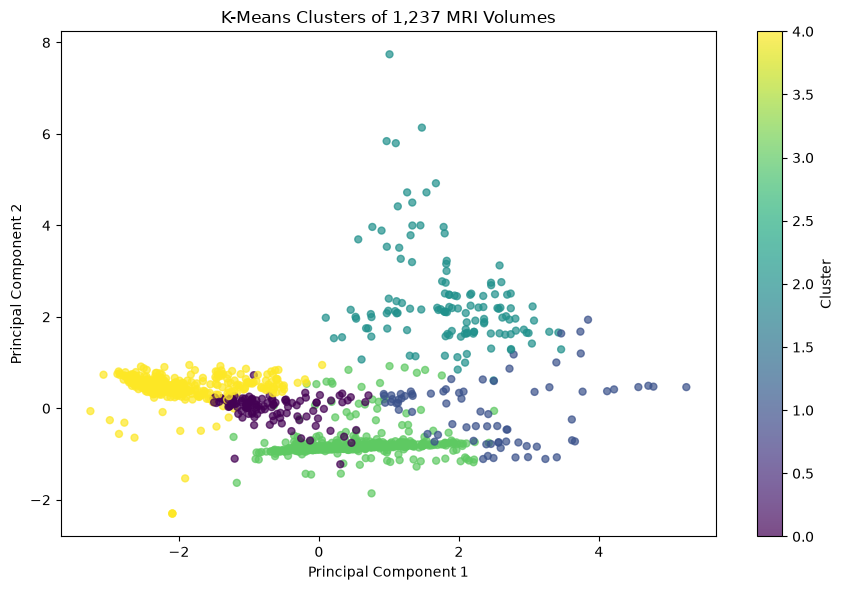

Variance explained by two components: 71.34 %


In [19]:
#Visualize the K-Means clusters

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the five features to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the K-Means clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=combined_df["kmeans_cluster"],
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters of 1,237 MRI Volumes")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

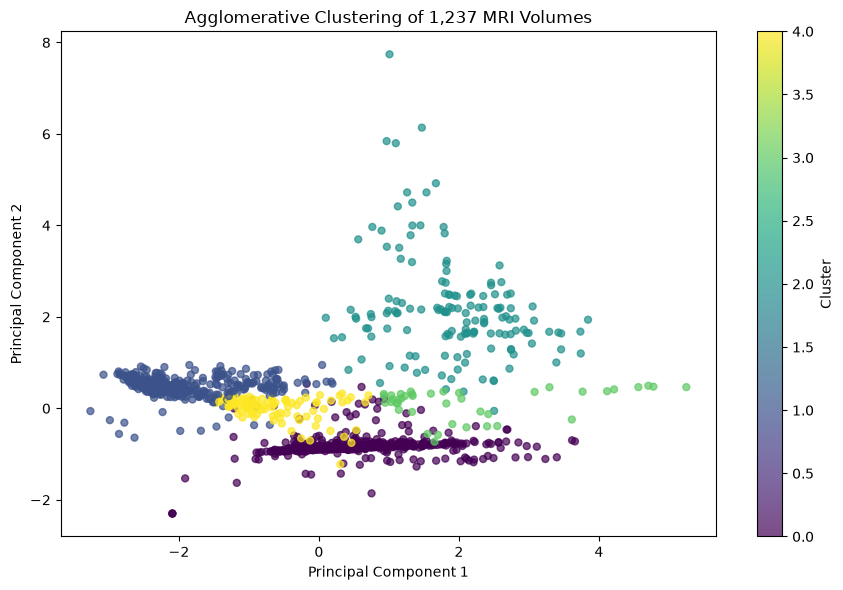

In [20]:
#Visualize Agglomerative clustering


import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=combined_df["agg_cluster"],
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering of 1,237 MRI Volumes")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

In [21]:
#save the clusters results tp csv


# Create a folder for project outputs
output_folder = os.path.join(os.getcwd(), "outputs")
os.makedirs(output_folder, exist_ok=True)

# Save all records and cluster assignments
results_path = os.path.join(
    output_folder,
    "lumbar_spine_clustering_results.csv"
)

combined_df.to_csv(results_path, index=False)

print("Results saved successfully!")
print("File location:", results_path)
print("Total MRI volumes saved:", len(combined_df))

Results saved successfully!
File location: C:\Users\hp-laptop\Downloads\lumbar spine project\outputs\lumbar_spine_clustering_results.csv
Total MRI volumes saved: 1237


In [23]:
# save the evaluation scores


# Save clustering evaluation results

evaluation_df = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative Clustering"
    ],
    "Number_of_Clusters": [5, 5],
    "Silhouette_Score": [
        kmeans_score,
        agg_score
    ],
    "Number_of_MRI_Volumes": [
        len(combined_df),
        len(combined_df)
    ]
})

evaluation_path = os.path.join(
    output_folder,
    "clustering_evaluation_scores.csv"
)

evaluation_df.to_csv(evaluation_path, index=False)

display(evaluation_df)

print("\nEvaluation scores saved to:")
print(evaluation_path)

,Algorithm,Number_of_Clusters,Silhouette_Score,Number_of_MRI_Volumes
0,K-Means,5,0.547391,1237
1,Agglomerative Clustering,5,0.545696,1237



Evaluation scores saved to:
C:\Users\hp-laptop\Downloads\lumbar spine project\outputs\clustering_evaluation_scores.csv


In [24]:
#Check how strongly clusters depend on dataset source


from sklearn.metrics import adjusted_rand_score

# Compare source dataset labels with clustering assignments
source_labels = combined_df["source_folder"]

kmeans_ari = adjusted_rand_score(
    source_labels,
    combined_df["kmeans_cluster"]
)

agg_ari = adjusted_rand_score(
    source_labels,
    combined_df["agg_cluster"]
)

print("Relationship between source dataset and clusters")
print("-" * 50)
print(f"K-Means ARI: {kmeans_ari:.4f}")
print(f"Agglomerative ARI: {agg_ari:.4f}")

Relationship between source dataset and clusters
--------------------------------------------------
K-Means ARI: 0.5714
Agglomerative ARI: 0.5901


In [25]:
#save the clusters summary


# Summarize the number of MRI volumes in each cluster

kmeans_summary = (
    combined_df.groupby("kmeans_cluster")
    .size()
    .reset_index(name="number_of_volumes")
)

agg_summary = (
    combined_df.groupby("agg_cluster")
    .size()
    .reset_index(name="number_of_volumes")
)

# Save both summaries
kmeans_summary.to_csv(
    os.path.join(output_folder, "kmeans_cluster_summary.csv"),
    index=False
)

agg_summary.to_csv(
    os.path.join(output_folder, "agglomerative_cluster_summary.csv"),
    index=False
)

print("Cluster summaries saved successfully!")

print("\nK-Means summary:")
display(kmeans_summary)

print("\nAgglomerative summary:")
display(agg_summary)

Cluster summaries saved successfully!

K-Means summary:


,kmeans_cluster,number_of_volumes
0,0,115
1,1,75
2,2,129
3,3,579
4,4,339



Agglomerative summary:


,agg_cluster,number_of_volumes
0,0,596
1,1,347
2,2,149
3,3,41
4,4,104


In [26]:
# check the saved project files

print("Project output files:\n")

for file in sorted(os.listdir(output_folder)):
    file_path = os.path.join(output_folder, file)

    if os.path.isfile(file_path):
        print(f"{file} — {os.path.getsize(file_path):,} bytes")

Project output files:

agglomerative_cluster_summary.csv — 65 bytes
clustering_evaluation_scores.csv — 156 bytes
kmeans_cluster_summary.csv — 68 bytes
lumbar_spine_clustering_results.csv — 104,202 bytes


In [27]:
#validate the clustering results

from sklearn.metrics import adjusted_rand_score

# Compare source folders with the clustering assignments
source_labels = combined_df["source_folder"]

kmeans_ari = adjusted_rand_score(
    source_labels,
    combined_df["kmeans_cluster"]
)

agg_ari = adjusted_rand_score(
    source_labels,
    combined_df["agg_cluster"]
)

print("Source-Dataset Validation")
print("-" * 35)
print(f"K-Means ARI: {kmeans_ari:.4f}")
print(f"Agglomerative ARI: {agg_ari:.4f}")

Source-Dataset Validation
-----------------------------------
K-Means ARI: 0.5714
Agglomerative ARI: 0.5901


In [28]:
#Final summary

# Step 32: Create project summary

project_summary = pd.DataFrame({
    "Item": [
        "Project Name",
        "Dataset",
        "Total MRI Volumes",
        "Number of Source Folders",
        "Features Used",
        "Number of Clusters",
        "K-Means Silhouette Score",
        "Agglomerative Silhouette Score"
    ],
    "Details": [
        "Lumbar Spine MRI Clustering",
        "Combined MRI volume dataset",
        len(combined_df),
        combined_df["source_folder"].nunique(),
        ", ".join(feature_columns),
        5,
        round(kmeans_score, 4),
        round(agg_score, 4)
    ]
})

summary_path = os.path.join(
    output_folder,
    "project_summary.csv"
)

project_summary.to_csv(summary_path, index=False)

display(project_summary)

print("\nProject summary saved to:")
print(summary_path)

,Item,Details
0,Project Name,Lumbar Spine MRI Clustering
1,Dataset,Combined MRI volume dataset
2,Total MRI Volumes,1237
3,Number of Source Folders,4
4,Features Used,"mean_intensity, std_intensity, median_intensit..."
5,Number of Clusters,5
6,K-Means Silhouette Score,0.5474
7,Agglomerative Silhouette Score,0.5457



Project summary saved to:
C:\Users\hp-laptop\Downloads\lumbar spine project\outputs\project_summary.csv


In [29]:
#save the final project results

# Step 33: Create a final results report

final_report = pd.DataFrame({
    "Metric": [
        "Total MRI volumes",
        "Source datasets",
        "Features used",
        "K-Means clusters",
        "Agglomerative clusters",
        "K-Means silhouette score",
        "Agglomerative silhouette score"
    ],
    "Result": [
        len(combined_df),
        combined_df["source_folder"].nunique(),
        len(feature_columns),
        combined_df["kmeans_cluster"].nunique(),
        combined_df["agg_cluster"].nunique(),
        round(kmeans_score, 4),
        round(agg_score, 4)
    ]
})

final_report_path = os.path.join(
    output_folder,
    "final_results_report.csv"
)

final_report.to_csv(final_report_path, index=False)

display(final_report)

print("\nFinal results report saved successfully!")
print(final_report_path)

,Metric,Result
0,Total MRI volumes,1237.0000
1,Source datasets,4.0000
2,Features used,5.0000
3,K-Means clusters,5.0000
4,Agglomerative clusters,5.0000
5,K-Means silhouette score,0.5474
6,Agglomerative silhouette score,0.5457



Final results report saved successfully!
C:\Users\hp-laptop\Downloads\lumbar spine project\outputs\final_results_report.csv


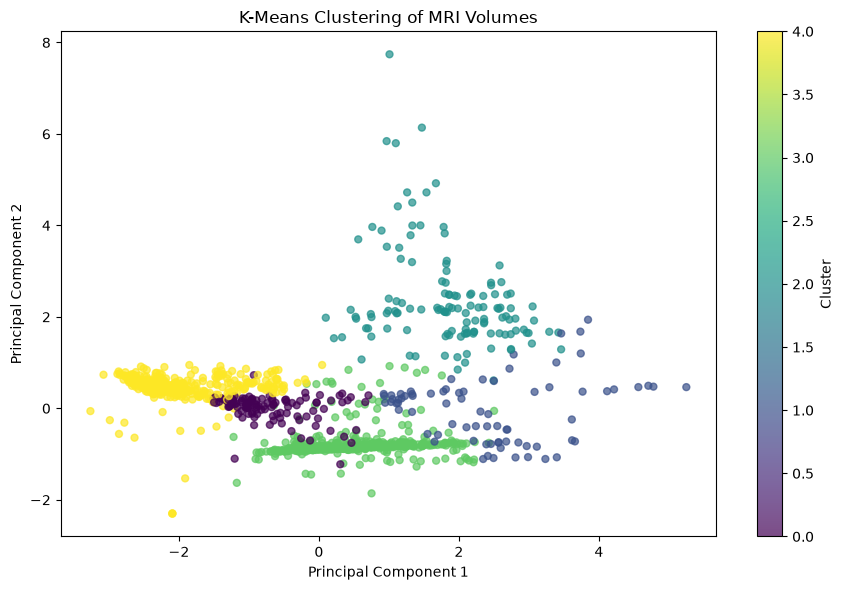

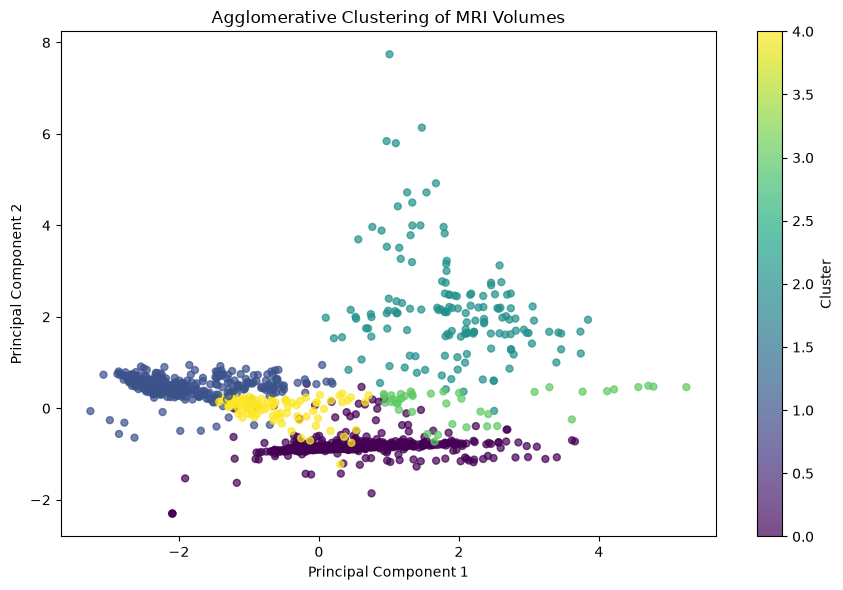

Both clustering graphs saved in: C:\Users\hp-laptop\Downloads\lumbar spine project\outputs


In [30]:
# Step 34: Save clustering graphs

import matplotlib.pyplot as plt
import os

# Save K-Means graph
plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=combined_df["kmeans_cluster"],
    cmap="viridis",
    s=25,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of MRI Volumes")
plt.colorbar(label="Cluster")
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "kmeans_clusters.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save Agglomerative graph
plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=combined_df["agg_cluster"],
    cmap="viridis",
    s=25,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering of MRI Volumes")
plt.colorbar(label="Cluster")
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "agglomerative_clusters.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Both clustering graphs saved in:", output_folder)

In [31]:
#Calculate the ARI Scores


from sklearn.metrics import adjusted_rand_score

# Compare source dataset with cluster assignments
source_labels = combined_df["source_folder"]

kmeans_ari = adjusted_rand_score(
    source_labels,
    combined_df["kmeans_cluster"]
)

agg_ari = adjusted_rand_score(
    source_labels,
    combined_df["agg_cluster"]
)

print("Source Dataset Validation")
print("-" * 35)
print(f"K-Means ARI: {kmeans_ari:.4f}")
print(f"Agglomerative ARI: {agg_ari:.4f}")

Source Dataset Validation
-----------------------------------
K-Means ARI: 0.5714
Agglomerative ARI: 0.5901


In [32]:
report_text = """
LUMBAR SPINE MRI CLUSTERING USING MACHINE LEARNING

1. INTRODUCTION
This project explores unsupervised machine learning techniques
to group lumbar spine MRI volumes according to numerical
image-intensity and volume-size features.

2. DATASET
The combined dataset contains 1,237 MRI volumes from four
source folders:
- processed_lsd: 515 volumes
- processed_osf: 34 volumes
- processed_spider: 210 volumes
- processed_tseg: 478 volumes

3. FEATURE EXTRACTION
Five features were used:
- Mean intensity
- Standard deviation of intensity
- Median intensity
- Nonzero voxel ratio
- Number of slices

The numerical features were standardized before clustering.

4. METHODS
Two unsupervised machine learning algorithms were applied:
- K-Means clustering with five clusters
- Agglomerative clustering with five clusters

Principal Component Analysis (PCA) was used to visualize
the clusters in two dimensions.

5. RESULTS
K-Means Silhouette Score: {kmeans_score:.4f}
Agglomerative Silhouette Score: {agg_score:.4f}

Both methods produced five clusters. K-Means had a marginally
higher silhouette score in this experiment.

6. LIMITATIONS
The clusters describe similarities in the selected image
features. They do not represent confirmed spinal conditions
or diagnoses. Source-dataset differences may influence the
results. Further validation and clinically meaningful labels
would be needed before any diagnostic claims.

7. CONCLUSION
This project demonstrates a workflow for extracting features
from MRI volumes and applying two unsupervised clustering
algorithms. The results provide a starting point for further
analysis and validation.
""".format(
    kmeans_score=kmeans_score,
    agg_score=agg_score
)

report_path = os.path.join(
    output_folder,
    "Lumbar_Spine_Project_Report.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("Project report saved successfully!")
print(report_path)

Project report saved successfully!
C:\Users\hp-laptop\Downloads\lumbar spine project\outputs\Lumbar_Spine_Project_Report.txt


In [33]:
from sklearn.metrics import adjusted_rand_score

kmeans_ari = adjusted_rand_score(
    combined_df["source_folder"],
    combined_df["kmeans_cluster"]
)

agg_ari = adjusted_rand_score(
    combined_df["source_folder"],
    combined_df["agg_cluster"]
)

print("Final Validation Results")
print("-" * 35)
print(f"K-Means ARI: {kmeans_ari:.4f}")
print(f"Agglomerative ARI: {agg_ari:.4f}")

Final Validation Results
-----------------------------------
K-Means ARI: 0.5714
Agglomerative ARI: 0.5901


In [34]:
print("Final project output files:\n")

for file in sorted(os.listdir(output_folder)):
    path = os.path.join(output_folder, file)

    if os.path.isfile(path):
        print(file)

Final project output files:

Lumbar_Spine_Project_Report.txt
agglomerative_cluster_summary.csv
agglomerative_clusters.png
clustering_evaluation_scores.csv
final_results_report.csv
kmeans_cluster_summary.csv
kmeans_clusters.png
lumbar_spine_clustering_results.csv
project_summary.csv


In [35]:
import os

print("Main project folder:")
print(os.getcwd())

print("\nJupyter Notebook files:")
for file in os.listdir(os.getcwd()):
    if file.endswith(".ipynb"):
        print(file)

Main project folder:
C:\Users\hp-laptop\Downloads\lumbar spine project

Jupyter Notebook files:
Lumbar_spine_ML_project.ipynb
